In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import spacy

In [2]:
df = pd.read_csv("../data/potential-talents - Aspiring human resources - seeking human resources.csv")

df.head()

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN


In [3]:
df = df.drop("fit",axis=1)

In [26]:
df.head()

,id,job_title,location,connection
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+


In [27]:
print(df["connection"].unique())

['85' '500+ ' '44' '1' '61' '2' '390' '57' '82' '5' '7' '16' '212' '409'
 '52' '455' '174' '268' '50' '4' '40' '18' '349' '155' '39' '64' '9' '415'
 '19' '71' '48' '103' '49']


In [4]:
df['connection'] = df['connection'].replace("500+ ","500")

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          104 non-null    int64 
 1   job_title   104 non-null    object
 2   location    104 non-null    object
 3   connection  104 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.4+ KB


In [5]:
df = df.drop_duplicates(subset=['job_title'])

In [31]:
df.head(60)


,id,job_title,location,connection
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44
3,4,People Development Coordinator at Ryan,"Denton, Texas",500
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1
6,7,Student at Humber College and Aspiring Human R...,Kanada,61
7,8,HR Senior Specialist,San Francisco Bay Area,500
9,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500
10,11,Student at Chapman University,"Lake Forest, California",2


In [33]:
df.columns

Index(['id', 'job_title', 'location', 'connection'], dtype='object')

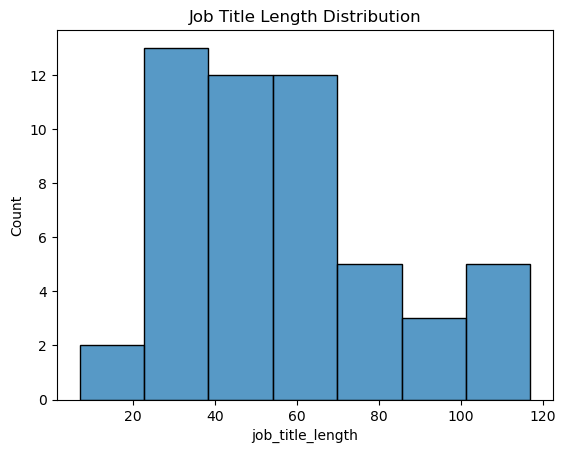

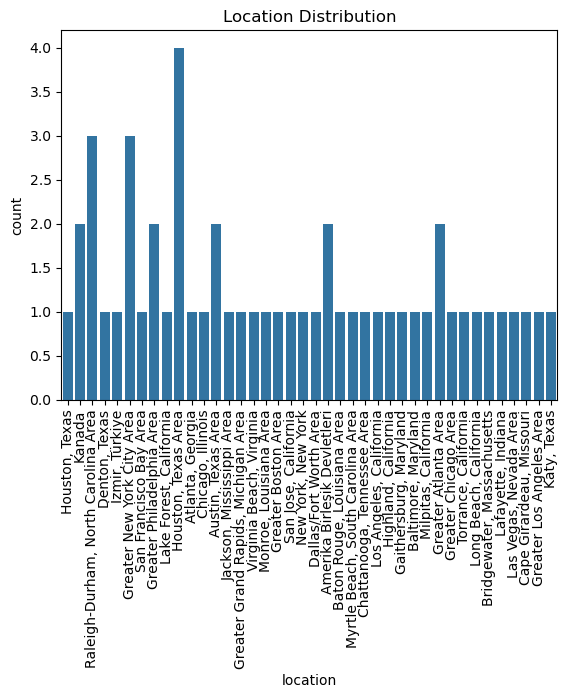

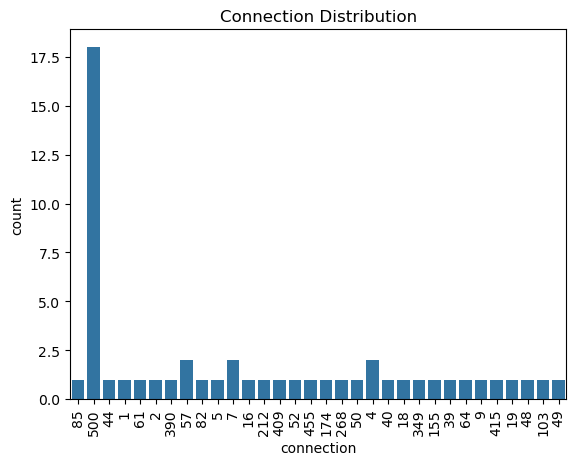

In [6]:
# Count the lengh of the title
df["job_title_length"] = df["job_title"].str.len()
sns.histplot(df["job_title_length"])
plt.title("Job Title Length Distribution")
plt.show()

# Used for location and connection count
sns.countplot(
    data = df,
    x = "location"
)
plt.xticks(rotation=90)
plt.title("Location Distribution")
plt.show()


sns.countplot(
    data= df,
    x = "connection"
)
plt.title("Connection Distribution")
plt.xticks(rotation=90)
plt.show()

In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")

df['job_title'] = df['job_title'].astype("str").str.strip()

In [ ]:
#!python -m spacy download en_core_web_sm

In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp(df['job_title'])

NameError: name 'doc' is not defined

In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")

def clean_title(text):
    doc = nlp(text)

    return [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
    ]

df["clean_job_title"] = df["job_title"].apply(clean_title)


ValueError: [E1041] Expected a string, Doc, or bytes as input, but got: <class 'list'>